# Student Performance Indicator

### Life Cycle of Machine Learing Project
    1- understanding the problem statment
    2- data collection
    3- data checks to perform
    4- eda
    5- data preprocessing
    6- model training
    7- choose best model
### 1) Problem statement
This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.

### 2) Data Collection
Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
The data consists of 8 column and 1000 rows.

In [66]:
# Basic Import
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings 
warnings.filterwarnings('ignore')

In [67]:
df = pd.read_csv('data/StudentsPerformance.csv')

### show top 5 records

In [68]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### shape of the dataset

In [69]:
df.shape

(1000, 8)

### Dataset columns

In [70]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

### 2.2 Dataset information
    gender : sex of students -> (Male/female)
    race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
    parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
    lunch : having lunch before test (standard or free/reduced)
    test preparation course : complete or not complete before test
    math score
    reading score
    writing score

### 3. Data Checks to perform
    1-Check Missing values
    2-Check Duplicates
    3-Check data type
    4-Check the number of unique values of each column
    5-Check statistics of data set
    6-Check various categories present in the different categorical column

3.1-Check Missing values

In [71]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

3.2-Check Duplicates

In [72]:
df.duplicated().sum()

np.int64(0)

3.3-Check data type 

In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


3.4-Check the number of unique values of each column


In [74]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

3.5-Check statistics of data set
 

In [75]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


3.6-Check various categories present in the different categorical column

3.7 - Exploring Data

In [76]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [77]:
print("Categories in: ")
print("gender: ", end = "")
print(list(df['gender'].unique()))
print('------------------------')
print("race/ethnicity: ", end = "")
print(list(df['race/ethnicity'].unique()))

print('------------------------')

print("parental level of education: ", end = "")
print(list(df['parental level of education'].unique()))

print('------------------------')

print("lunch: ", end = "")
print(list(df['lunch'].unique()))

print('------------------------')

print("test preparation course: ", end = "")
print(list(df['test preparation course'].unique()))

Categories in: 
gender: ['female', 'male']
------------------------
race/ethnicity: ['group B', 'group C', 'group A', 'group D', 'group E']
------------------------
parental level of education: ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
------------------------
lunch: ['standard', 'free/reduced']
------------------------
test preparation course: ['none', 'completed']


In [78]:
list(df['gender'].unique())

['female', 'male']

In [79]:
numeric_features = df.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = df.select_dtypes(include = ['object', 'category']).columns

print(f"We have {len(numeric_features)} numeric features: {list(numeric_features)}")
print(f"We have {len(categorical_features)} categorical features: {list(categorical_features)}")

We have 3 numeric features: ['math score', 'reading score', 'writing score']
We have 5 categorical features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [80]:
df['total_score'] = df['math score'] + df['reading score'] + df['writing score']
df['average_score'] = df['total_score']/3
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [81]:
full_mark_math = df[df['math score'] == 100]['average_score'].count()
full_mark_reading = df[df['reading score'] == 100]['average_score'].count()
full_mark_writing = df[df['writing score'] == 100]['average_score'].count()


full_less_than_30_math = df[df['math score'] < 30]['average_score'].count()
full_less_than_30_reading = df[df['reading score'] < 30]['average_score'].count()
full_less_than_30_writing = df[df['writing score'] < 30]['average_score'].count()

print(f"Number of students who get full mark in math if {full_mark_math}")
print(f"Number of students who get full mark in reading if {full_mark_reading}")
print(f"Number of students who get full mark in writing if {full_mark_writing}")
print("---------------------------------------------------")
print(f"Number of students who get less than 30 in math if {full_less_than_30_math}")
print(f"Number of students who get less than 30 in reading if {full_less_than_30_reading}")
print(f"Number of students who get less than 30 in writing if {full_less_than_30_writing}")

Number of students who get full mark in math if 7
Number of students who get full mark in reading if 17
Number of students who get full mark in writing if 14
---------------------------------------------------
Number of students who get less than 30 in math if 14
Number of students who get less than 30 in reading if 8
Number of students who get less than 30 in writing if 9


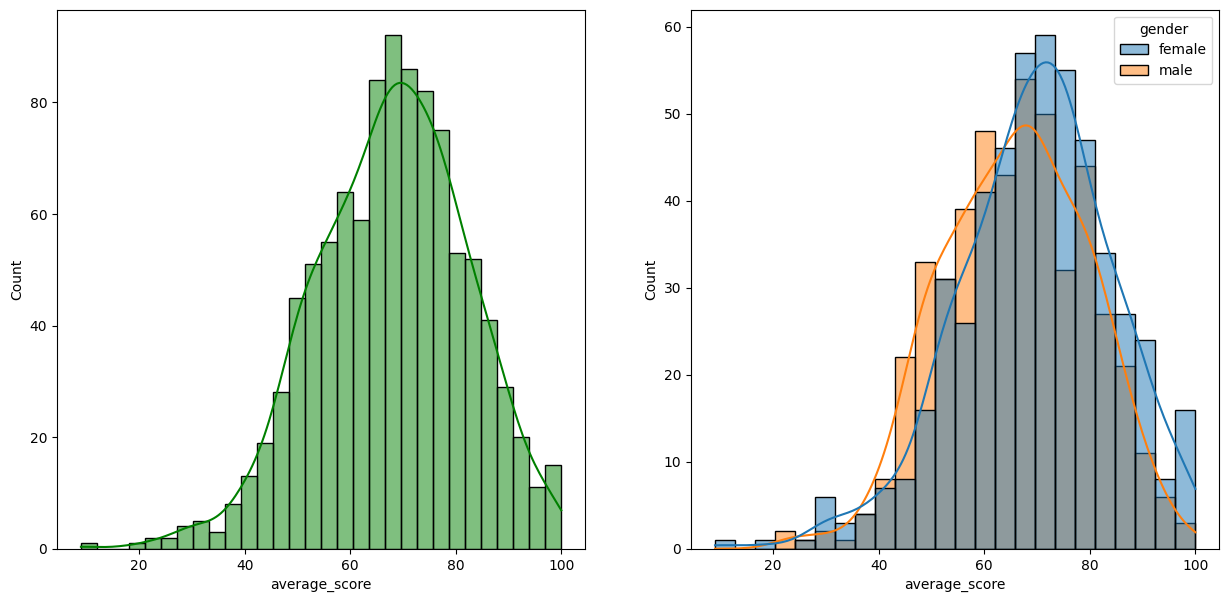

In [82]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='average_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='average_score',kde=True,hue='gender')
plt.show()

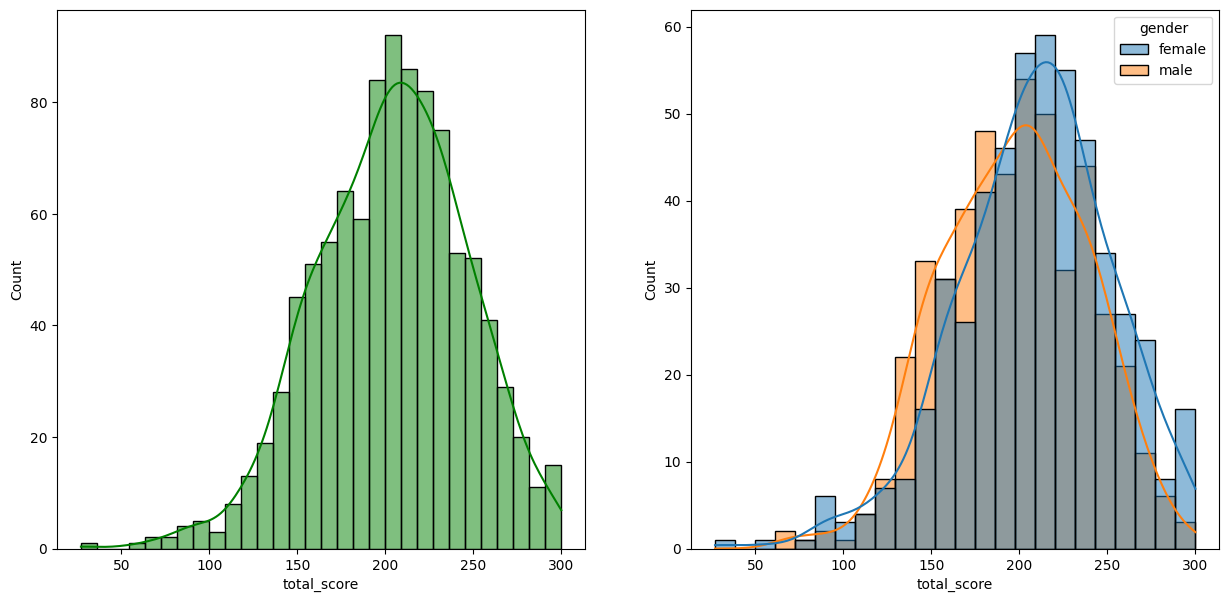

In [83]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='total_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total_score',kde=True,hue='gender')
plt.show()

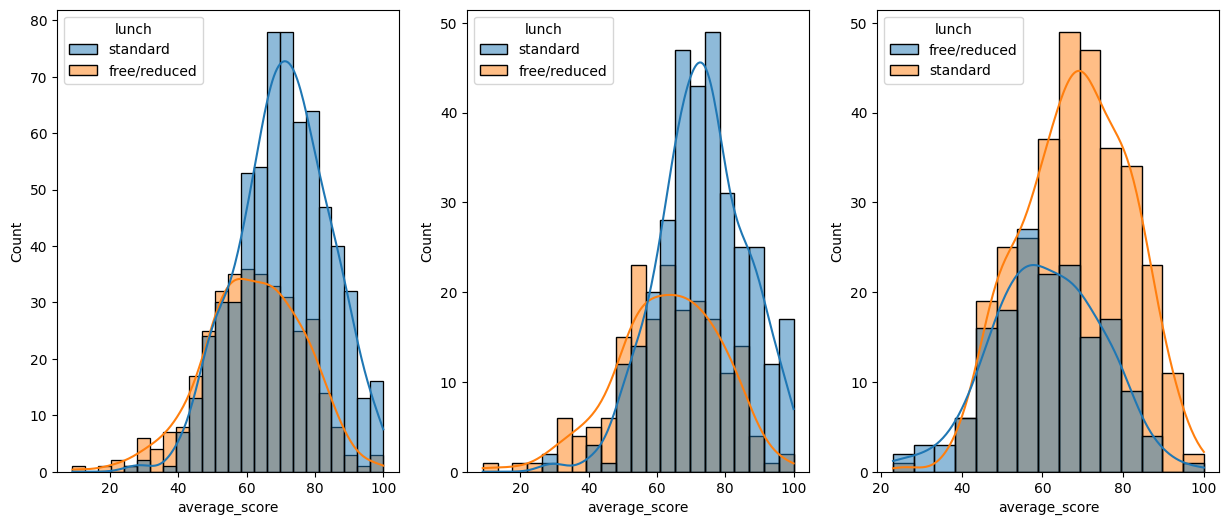

In [84]:
plt.subplots(1,3,figsize=(15,6))
plt.subplot(131)
sns.histplot(data=df,x='average_score',kde=True,hue='lunch')
plt.subplot(132)
sns.histplot(data=df[df.gender=='female'],x='average_score',kde=True,hue='lunch')
plt.subplot(133)
sns.histplot(data=df[df.gender=='male'],x='average_score',kde=True,hue='lunch')
plt.show()

### Training Pipline

    1- prepare Data (X) and Traget (y)
    2- preprocess (encoding categorical features, feature scaling,..)
    3- train,test,validation split
    4- baseline model => linear ragression
    5- try more than one model(svr,knn,descion tree, ensumble trees(xgboos,catboos), svr,..) or try ensumble learning
    6- model evalution
    7- choose the best model (- . -)

In [85]:
X = df.drop('total_score',axis = 1)
X.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


In [86]:
y = df['total_score']
y.head()

0    218
1    247
2    278
3    148
4    229
Name: total_score, dtype: int64

In [87]:
numeric_features = X.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X.select_dtypes(include = ['object', 'category']).columns

print(f"We have {len(numeric_features)} numeric features: {list(numeric_features)}")
print(f"We have {len(categorical_features)} categorical features: {list(categorical_features)}")

print('-------------------------------------------------------------------------------')
print("Categories in: ")
print("gender: ", end = "")
print(list(X['gender'].unique()))
print('------------------------')
print("race/ethnicity: ", end = "")
print(list(X['race/ethnicity'].unique()))

print('------------------------')

print("parental level of education: ", end = "")
print(list(X['parental level of education'].unique()))

print('------------------------')

print("lunch: ", end = "")
print(list(X['lunch'].unique()))

print('------------------------')

print("test preparation course: ", end = "")
print(list(X['test preparation course'].unique()))

We have 4 numeric features: ['math score', 'reading score', 'writing score', 'average_score']
We have 5 categorical features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
-------------------------------------------------------------------------------
Categories in: 
gender: ['female', 'male']
------------------------
race/ethnicity: ['group B', 'group C', 'group A', 'group D', 'group E']
------------------------
parental level of education: ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
------------------------
lunch: ['standard', 'free/reduced']
------------------------
test preparation course: ['none', 'completed']


In [88]:
numeric_features = X.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X.select_dtypes(include = ['object', 'category']).columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
ohe = OneHotEncoder(handle_unknown='ignore',sparse_output=False).set_output(transform='pandas')
scaler = StandardScaler().set_output(transform='pandas')
ohe_transformed = ohe.fit_transform(X[categorical_features])
X = pd.concat([X,ohe_transformed],axis = 1).drop(categorical_features,axis=1)
X.head()

,math score,reading score,writing score,average_score,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,...,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_free/reduced,lunch_standard,test preparation course_completed,test preparation course_none
0,72,72,74,72.666667,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,69,90,88,82.333333,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,90,95,93,92.666667,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
3,47,57,44,49.333333,0.0,1.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,76,78,75,76.333333,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [89]:
X.shape

(1000, 21)

In [98]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)  

In [99]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def evaluation(y_true,y_pred):
    R2_score = r2_score(y_true,y_pred)
    mae = mean_absolute_error(y_true,y_pred)
    mse = mean_squared_error(y_true,y_pred)
    
    return R2_score, mae, mse

In [100]:
models = {
'Linear Regression': LinearRegression(),
'Ridge Regression': Ridge(),
'Lasso Regression': Lasso(),
'KNeighbors Regressor': KNeighborsRegressor(),
'Decision Tree Regressor': DecisionTreeRegressor(),
'Random Forest Regressor': RandomForestRegressor(),
'AdaBoost Regressor': AdaBoostRegressor(),
'Support Vector Regressor': SVR(),
'CatBoost Regressor': CatBoostRegressor(verbose=False),
'XGBoost Regressor': XGBRegressor(),
}

r2_score_list = []
model_list = []
for i in models:
    model = models[i]

    #! Train the model
    model.fit(X_train,y_train)

    #! Make predictions
    y_test_pred = model.predict(X_test)
    y_train_pred = model.predict(X_train)

    # ! Evaluate the model
    r2_test, mae_test, mse_test = evaluation(y_test,y_test_pred)
    r2_train, mae_train, mse_train = evaluation(y_train,y_train_pred)

    print(f"{i} Model performance: ")
    print(f"training set => R2: {r2_train}, MAE: {mae_train}, MSE: {mse_train}")
    print(f"testing set => R2: {r2_test}, MAE: {mae_test}, MSE: {mse_test}") 
    model_list.append(i)
    r2_score_list.append(r2_test)
    print("-------------------------------------------------------------")

Linear Regression Model performance: 
training set => R2: 1.0, MAE: 1.4619416788264062e-14, MSE: 5.586397386413117e-28
testing set => R2: 1.0, MAE: 1.4850343177386093e-14, MSE: 5.785821423252989e-28
-------------------------------------------------------------
Ridge Regression Model performance: 
training set => R2: 0.9999998316251493, MAE: 0.014076183403502397, MSE: 0.00030224042437982713
testing set => R2: 0.9999998111078167, MAE: 0.014495701658506449, MSE: 0.00036442951937314664
-------------------------------------------------------------
Lasso Regression Model performance: 
training set => R2: 0.999442910884498, MAE: 0.8002753770375296, MSE: 0.9999999999999994
testing set => R2: 0.9994325936267315, MAE: 0.8237354633452267, MSE: 1.0946966052810287
-------------------------------------------------------------
KNeighbors Regressor Model performance: 
training set => R2: 0.8724228043440597, MAE: 11.798000000000002, MSE: 229.0068
testing set => R2: 0.8120032295666338, MAE: 14.537999999

In [101]:
pd.DataFrame(list(zip(model_list, r2_score_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"],ascending=False)

,Model Name,R2_Score
0,Linear Regression,1.000000
1,Ridge Regression,1.000000
2,Lasso Regression,0.999433
4,Decision Tree Regressor,0.997681
9,XGBoost Regressor,0.997368
5,Random Forest Regressor,0.996245
8,CatBoost Regressor,0.994893
6,AdaBoost Regressor,0.988506
3,KNeighbors Regressor,0.812003
7,Support Vector Regressor,0.700536
